In [2]:
import pandas as pd

In [3]:
df = pd.read_csv("ecommerce_sales_practice.csv")

In [65]:
# Display the first 5 rows of the dataset.
df.head()

,order_id,customer_age,city,product,category,unit_price,quantity,payment_method,rating,total_sales
0,ORD2001,27.0,Riyadh,Webcam,Accessories,103.40,3,Card,5.0,310.20
1,ORD2002,57.0,Jeddah,Phone,Mobile,1156.62,5,Cash,1.0,5783.10
2,ORD2003,65.0,Riyadh,Webcam,Accessories,51.65,5,Cash,1.0,258.25
3,ORD2004,54.0,Jeddah,Tablet,Mobile,239.99,1,Cash,5.0,239.99
4,ORD2005,64.0,Jeddah,Tablet,Mobile,816.38,2,Bank Transfer,3.0,1632.76


In [ ]:
# How many rows and columns are in the dataset?
df.shape

(120, 10)

In [ ]:
# What are the column names?
df.columns

Index(['order_id', 'customer_age', 'city', 'product', 'category', 'unit_price',
       'quantity', 'payment_method', 'rating', 'total_sales'],
      dtype='str')

In [ ]:
# What are the unique values in the city column?
df['city'].unique()

<StringArray>
['Riyadh', 'Jeddah', 'Madinah', 'Abha', 'Dammam', nan]
Length: 6, dtype: str

In [ ]:
# How many unique products are in the dataset?
df['product'].nunique()

8

In [ ]:
# How many orders are there for each payment_method?
print(df['payment_method'].value_counts())

payment_method
Cash             32
Bank Transfer    32
Card             28
Apple Pay        26
Name: count, dtype: int64


In [ ]:
# What is the average unit_price?
print(df['unit_price'].mean())

452.34250000000003


In [ ]:
# What is the highest total_sales value?
print(df['total_sales'].max())

7246.5


In [52]:
# How many orders have a quantity greater than 3?
print((df['quantity'] > 3).sum())

46


In [40]:
# Display all orders where city is 'Madinah'.
df[df['city'] == 'Madinah'].head()

,order_id,customer_age,city,product,category,unit_price,quantity,payment_method,rating,total_sales,discounted_price,order_size
6,ORD2007,56.0,Madinah,Laptop,Computers,1564.93,2,Cash,4.0,3129.86,1408.437,Large
11,ORD2012,45.0,Madinah,Webcam,Accessories,56.91,5,Cash,5.0,284.55,51.219,Small
23,ORD2024,49.0,Madinah,Webcam,Accessories,33.66,4,Apple Pay,3.0,134.64,30.294,Small
25,ORD2026,63.0,Madinah,Monitor,Computers,378.47,4,Apple Pay,3.0,1513.88,340.623,Large
27,ORD2028,60.0,Madinah,Monitor,Computers,176.27,3,NaN,5.0,528.81,158.643,Small


In [ ]:
# What is the average rating?
print(df['rating'].mean())

3.847457627118644


In [50]:
# What is the average unit_price for the 'Laptop' product?
print(df[df['product'] == 'Laptop']['unit_price'].mean())

1207.8554545454544


In [ ]:
# How many orders have a total_sales greater than 1000?
print((df['total_sales'] > 1000).sum())

46


In [ ]:
# Display the order with the highest total_sales.
print(df.loc[df['total_sales'].idxmax()])

order_id                ORD2074
customer_age               67.0
city                     Riyadh
product                  Laptop
category              Computers
unit_price               1449.3
quantity                      5
payment_method    Bank Transfer
rating                      3.0
total_sales              7246.5
Name: 73, dtype: object


In [47]:
print(df['total_sales'].max())

7246.5


In [ ]:
# What is the average customer_age for customers in Riyadh?
print(df[df['city'] == 'Riyadh']['customer_age'].mean())

43.19047619047619


In [ ]:
# Calculate the average total_sales for each city.
df.groupby('city')['total_sales'].mean()

city
Abha       1621.710000
Dammam     1591.985769
Jeddah     1276.696818
Madinah     888.560833
Riyadh     1308.530000
Name: total_sales, dtype: float64


In [ ]:
# Find the total quantity sold for each product.
df.groupby('product')['quantity'].sum()

product
Headphones    48
Keyboard      18
Laptop        33
Monitor       63
Mouse         40
Phone         60
Tablet        48
Webcam        47
Name: quantity, dtype: int64

In [6]:
# Which payment_method has the highest average total_sales?
print(df.groupby('payment_method')['total_sales'].mean().idxmax())

Bank Transfer


In [23]:
# Create a new column called discounted_price that applies a 10% discount to unit_price.
df['discounted_price'] = df['unit_price'] * 0.90
df[['unit_price', 'discounted_price']].head()

,unit_price,discounted_price
0,103.40,93.060
1,1156.62,1040.958
2,51.65,46.485
3,239.99,215.991
4,816.38,734.742


In [20]:
# Create a new column called order_size:
df['order_size'] = df['total_sales'].apply(lambda x: 'Large' if x >= 1000 else 'Small')
df[['total_sales', 'order_size']].head()

,total_sales,order_size
0,310.20,Small
1,5783.10,Large
2,258.25,Small
3,239.99,Small
4,1632.76,Large


In [26]:
# How many null values are there in each column?
df.isnull().sum()

order_id            0
customer_age        3
city                2
product             0
category            0
unit_price          0
quantity            0
payment_method      2
rating              2
total_sales         0
discounted_price    0
order_size          0
dtype: int64

In [34]:
# How many rows contain at least one null value?
print(df.isnull().any(axis=1).sum())

7


In [ ]:
# Fill missing rating values with the average rating.
df['rating'] = df['rating'].fillna(df['rating'].mean())

# Check 
print(df['rating'].isnull().sum())

0


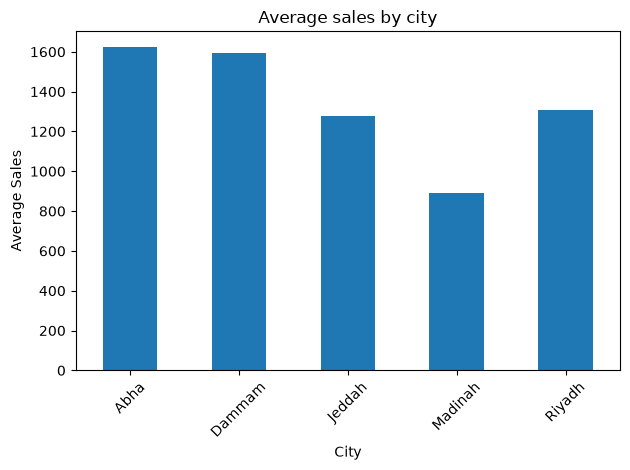

In [4]:
import matplotlib.pyplot as plt

city_sales = df.groupby('city')['total_sales'].mean()

city_sales.plot(kind='bar')

plt.title('Average sales by city')
plt.xlabel('City')
plt.ylabel('Average Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()